### Domain-specific area and the objectives of the project

The project domain focuses on real estate pricing, specifically predicting residential house sale prices using the Ames Housing dataset. This domain is important because accurate price estimation supports buyers, sellers, appraisers, and policy makers by providing data-driven valuations that fairly reflect property traits.

Objectives: The primary objective of this project is to build a simple linear regression model that can accurately predict house prices from data with multiple different data points into consideration.

Benefits of using linear regression: Linear regression is appropriate for this domain as house prices are a continuous numeric target and many relationships between predictors and price are approximately linear or can become linear with some simple transformations. Linear models are easy to interpret and provide a clear baseline to compare against more complex models.

The insights produced from this project can have positive effects in the the real estate industry. By identifying the different traits of a house that could affect its pricing, real estate agents can give more accurate price estimations to their clients. Furthermore, by training and demonstrating models capable of making accurate predictions, real estate agents will be encouraged to acquire and analyse data related to the features employed. This could lead to the development of further specialised models for other forms of real estate, hence improving industry decision-making.

### Dataset Description

The dataset I've chosen to use in this project is The Ames Housing Dataset. It is a widely used dataset for training and testing machine learning models for real estate predictions. It contains a wide range of information about homes sold in Ames, Iowa, USA between 2006 and 2010. This dataset is suitable for this project is it contains many different features that can be used to predict house prices.

Size of dataset : 82 columns and 2930 instances

Data Types : Numerical and Categorical

### Data Preparation & Inspection

In [1]:
# Importing all packages here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score

C:\Users\Enzo\AppData\Local\Temp\ipykernel_5640\2087139318.py:2: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
# Loading the dataset
df = pd.read_csv('AmesHousing.csv')

# Reading top few rows
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
# Quick look at the dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [4]:
# Quick look at the statistical summary of the dataset
df.describe()

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


In [5]:
# Checking for missing values
missing_values = df.isnull().sum()

# Display only columns with missing values
missing_values = missing_values[missing_values > 0]
missing_values

Lot Frontage       490
Alley             2732
Mas Vnr Type      1775
Mas Vnr Area        23
Bsmt Qual           80
Bsmt Cond           80
Bsmt Exposure       83
BsmtFin Type 1      80
BsmtFin SF 1         1
BsmtFin Type 2      81
BsmtFin SF 2         1
Bsmt Unf SF          1
Total Bsmt SF        1
Electrical           1
Bsmt Full Bath       2
Bsmt Half Bath       2
Fireplace Qu      1422
Garage Type        157
Garage Yr Blt      159
Garage Finish      159
Garage Cars          1
Garage Area          1
Garage Qual        159
Garage Cond        159
Pool QC           2917
Fence             2358
Misc Feature      2824
dtype: int64

In [6]:
# Since the dataset contains both numerical and categorical features, we will separate each data type by data and column for easier checking.

# Numerical data
numerical_data = df.select_dtypes(include=['number'])
numerical_cols = df.select_dtypes(include=['number']).columns

print(numerical_data.head())
print(numerical_cols)

   Order        PID  MS SubClass  Lot Frontage  Lot Area  Overall Qual  \
0      1  526301100           20         141.0     31770             6   
1      2  526350040           20          80.0     11622             5   
2      3  526351010           20          81.0     14267             6   
3      4  526353030           20          93.0     11160             7   
4      5  527105010           60          74.0     13830             5   

   Overall Cond  Year Built  Year Remod/Add  Mas Vnr Area  ...  Wood Deck SF  \
0             5        1960            1960         112.0  ...           210   
1             6        1961            1961           0.0  ...           140   
2             6        1958            1958         108.0  ...           393   
3             5        1968            1968           0.0  ...             0   
4             5        1997            1998           0.0  ...           212   

   Open Porch SF  Enclosed Porch  3Ssn Porch  Screen Porch  Pool Area  \
0

In [7]:
# Categorical data (text)
text_data = df.select_dtypes(include=['object'])
text_cols = df.select_dtypes(include=['object']).columns

print(text_data.head())
print(text_cols)

  MS Zoning Street Alley Lot Shape Land Contour Utilities Lot Config  \
0        RL   Pave   NaN       IR1          Lvl    AllPub     Corner   
1        RH   Pave   NaN       Reg          Lvl    AllPub     Inside   
2        RL   Pave   NaN       IR1          Lvl    AllPub     Corner   
3        RL   Pave   NaN       Reg          Lvl    AllPub     Corner   
4        RL   Pave   NaN       IR1          Lvl    AllPub     Inside   

  Land Slope Neighborhood Condition 1  ... Garage Type Garage Finish  \
0        Gtl        NAmes        Norm  ...      Attchd           Fin   
1        Gtl        NAmes       Feedr  ...      Attchd           Unf   
2        Gtl        NAmes        Norm  ...      Attchd           Unf   
3        Gtl        NAmes        Norm  ...      Attchd           Fin   
4        Gtl      Gilbert        Norm  ...      Attchd           Fin   

  Garage Qual Garage Cond Paved Drive Pool QC  Fence Misc Feature Sale Type  \
0          TA          TA           P     NaN    NaN   

In [8]:
# Missing values for numerical data
numerical_missing = numerical_data.isnull().sum()
numerical_missing = numerical_missing[numerical_missing > 0]
numerical_missing

Lot Frontage      490
Mas Vnr Area       23
BsmtFin SF 1        1
BsmtFin SF 2        1
Bsmt Unf SF         1
Total Bsmt SF       1
Bsmt Full Bath      2
Bsmt Half Bath      2
Garage Yr Blt     159
Garage Cars         1
Garage Area         1
dtype: int64

### Going through each numerical value column with missing values in order

In [9]:
# Lot Frontage
# There is one more column related to Lots that is also numerical which is Lot Area.
# I will be using the Lot Area to determine how to deal with the missing values in Lot Frontage.

# Checking correlation between Lot Frontage and Lot Area
lot_correlation = numerical_data[['Lot Frontage', 'Lot Area']].corr()
lot_correlation

,Lot Frontage,Lot Area
Lot Frontage,1.000000,0.491313
Lot Area,0.491313,1.000000


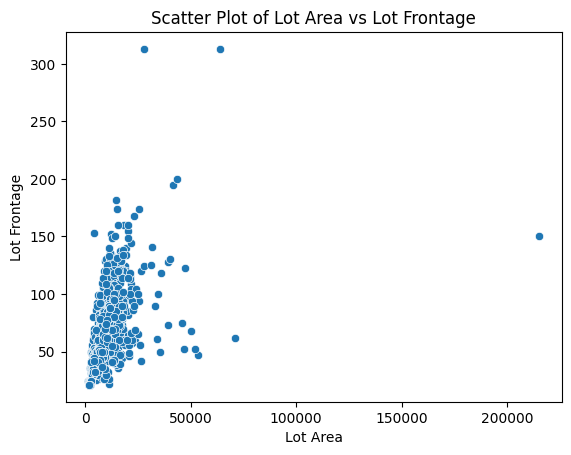

In [10]:
# Scatter Plot to visualize the relationship between Lot Area and Lot Frontage
plt.title('Scatter Plot of Lot Area vs Lot Frontage')
sns.scatterplot(data=numerical_data, x='Lot Area', y='Lot Frontage')

plt.show()

With a correlation value of 0.491 and the scatter plot not showing any trend in the data, the 2 values are not strongly correlated.
I will fill in the missing data using the median value.

In [11]:
# Filling in missing values for Lot Frontage
df.fillna({'Lot Frontage': df['Lot Frontage'].median()}, inplace=True)

In [12]:
# Mas Vnr Area
# According to the dataset doccumentatioin, missing values in this column can mean that there is no Masonry Veneer for the house.
# This is taken from Mas Vnr Type column where NA means None.
df['Mas Vnr Area'].isna().sum()

23

In [13]:
# Get rows where Mas Vnr Area is missing
df[df['Mas Vnr Area'].isna()][['Mas Vnr Type', 'Mas Vnr Area']]

,Mas Vnr Type,Mas Vnr Area
55,NaN,NaN
484,NaN,NaN
517,NaN,NaN
538,NaN,NaN
867,NaN,NaN
1095,NaN,NaN
1119,NaN,NaN
1122,NaN,NaN
1127,NaN,NaN
1184,NaN,NaN


In [14]:
df[df['Mas Vnr Area'].isna()][['Mas Vnr Type', 'Mas Vnr Area']].isna().sum()

Mas Vnr Type    23
Mas Vnr Area    23
dtype: int64

In [15]:
# Since the number of missing values in Mas Vnr Area corresponds to the number of 'None' in Mas Vnr Type, I will fill in the missing values with 0.
df['Mas Vnr Area'].fillna(0, inplace=True)


C:\Users\Enzo\AppData\Local\Temp\ipykernel_5640\894896600.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Mas Vnr Area'].fillna(0, inplace=True)


In [16]:
# Basement Related Columns
df[df['Bsmt Full Bath'].isna()][['PID','BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath', 'Bsmt Half Bath']]

,PID,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath
1341,903230120,NaN,NaN,NaN,NaN,NaN,NaN
1497,908154080,0.0,0.0,0.0,0.0,NaN,NaN


In [17]:
# Since there are only 2 instances of missing values in these columns, I will drop these rows from the dataset.
df.dropna(subset=['Bsmt Full Bath', 'Bsmt Half Bath'], inplace=True)

In [18]:
# Garage Year Built
df[df['Garage Yr Blt'].isna()][['Garage Type', 'Garage Yr Blt']]

,Garage Type,Garage Yr Blt
27,NaN,NaN
119,NaN,NaN
125,NaN,NaN
129,NaN,NaN
130,NaN,NaN
...,...,...
2913,NaN,NaN
2916,NaN,NaN
2918,NaN,NaN
2919,NaN,NaN


In [19]:
# The na values for the year built of the garage corresponds to the house having no garage.
# Therefore, I will fill in the missing values with the year the house was built.
df['Garage Yr Blt'] = df['Garage Yr Blt'].fillna(df['Year Built'])

In [20]:
# Garage Cars and Garage Area
df[df['Garage Cars'].isna()][['PID', 'Garage Cars', 'Garage Area']]

,PID,Garage Cars,Garage Area
2236,910201180,NaN,NaN


In [21]:
df[df['Garage Area'].isna()][['PID', 'Garage Cars', 'Garage Area']]

,PID,Garage Cars,Garage Area
2236,910201180,NaN,NaN


In [22]:
# Since missing garage cars and area are the same instance, I will drop this instance
df.dropna(subset=['Garage Cars', 'Garage Area'], inplace=True)

In [23]:
# Double checking for any remaining numerical missing values
numerical_data = df.select_dtypes(include=['number'])
numerical_cols = df.select_dtypes(include=['number']).columns

numerical_missing = numerical_data.isnull().sum()
numerical_missing = numerical_missing[numerical_missing > 0]
numerical_missing

Series([], dtype: int64)

Going through categorical data with missing values

In [24]:
# Missing categorical data
categorical_data = df.select_dtypes(include=['object'])
categorical_cols = df.select_dtypes(include=['object']).columns

categorical_missing = categorical_data.isnull().sum()
categorical_missing = categorical_missing[categorical_missing > 0]
categorical_missing

Alley             2729
Mas Vnr Type      1772
Bsmt Qual           78
Bsmt Cond           78
Bsmt Exposure       81
BsmtFin Type 1      78
BsmtFin Type 2      79
Electrical           1
Fireplace Qu      1420
Garage Type        157
Garage Finish      158
Garage Qual        158
Garage Cond        158
Pool QC           2914
Fence             2357
Misc Feature      2821
dtype: int64

In [25]:
# I will be dropping a few of the columns that have a high number of missing values and are not significant to the analysis.
# These columns are Alley, Pool QC, Fence, Misc Feature + Misc Val
df.drop(columns=['Alley', 'Pool QC', 'Fence', 'Misc Feature','Misc Val'], inplace=True)

In [26]:
# Electrical
# There is only 1 missing value in this column. I will drop this row.
df.dropna(subset=['Electrical'], inplace=True)

In [27]:
# The rest of the missing values are due to the absence of certain features in the house (eg. Fireplace, Garage, Basement etc.)
# Therefore, I will be filling in the missing values with 'None'
none_cols = categorical_missing.index.tolist()
none_cols.remove('Electrical')  
none_cols.remove('Alley') 
none_cols.remove('Pool QC') 
none_cols.remove('Misc Feature') 
none_cols.remove('Fence') 
none_cols


['Mas Vnr Type',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin Type 2',
 'Fireplace Qu',
 'Garage Type',
 'Garage Finish',
 'Garage Qual',
 'Garage Cond']

In [28]:
df[none_cols] = df[none_cols].fillna('none')

In [29]:
# Checking for any remaining categorical missing values
categorical_data = df.select_dtypes(include=['object'])
categorical_cols = df.select_dtypes(include=['object']).columns

categorical_missing = categorical_data.isnull().sum()
categorical_missing = categorical_missing[categorical_missing > 0]
categorical_missing

Series([], dtype: int64)

In [30]:
# Last part of data cleaning is to change the rating systems for some of the columns from categorical to numerical.
# This first one consists of rating colums that have 5 levels of ratings.
ratings = ['Ex','Gd','TA','Fa','Po']

# Search for columns that contain rating values
rating_cols= [col for col in df.columns if df[col].isin(ratings).any()]

df[rating_cols]

,Exter Qual,Exter Cond,Bsmt Qual,Bsmt Cond,Bsmt Exposure,Heating QC,Kitchen Qual,Fireplace Qu,Garage Qual,Garage Cond
0,TA,TA,TA,Gd,Gd,Fa,TA,Gd,TA,TA
1,TA,TA,TA,TA,No,TA,TA,none,TA,TA
2,TA,TA,TA,TA,No,TA,Gd,none,TA,TA
3,Gd,TA,TA,TA,No,Ex,Ex,TA,TA,TA
4,TA,TA,Gd,TA,No,Gd,TA,TA,TA,TA
...,...,...,...,...,...,...,...,...,...,...
2925,TA,TA,TA,TA,Av,TA,TA,none,TA,TA
2926,TA,TA,Gd,TA,Av,TA,TA,none,TA,TA
2927,TA,TA,Gd,TA,Av,TA,TA,none,none,none
2928,TA,TA,Gd,TA,Av,Gd,TA,TA,TA,TA


In [31]:
# Basement Exposure has different rating so we'll drop it from this list
rating_cols.remove('Bsmt Exposure')
rating_cols

['Exter Qual',
 'Exter Cond',
 'Bsmt Qual',
 'Bsmt Cond',
 'Heating QC',
 'Kitchen Qual',
 'Fireplace Qu',
 'Garage Qual',
 'Garage Cond']

In [32]:
# Map out the rating for each rating column
for col in rating_cols:
    df[col] = df[col].map({'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'none': 0, 'NA': 0})

# Verify the changes
print(df[rating_cols].head())

   Exter Qual  Exter Cond  Bsmt Qual  Bsmt Cond  Heating QC  Kitchen Qual  \
0           3           3          3          4           2             3   
1           3           3          3          3           3             3   
2           3           3          3          3           3             4   
3           4           3          3          3           5             5   
4           3           3          4          3           4             3   

   Fireplace Qu  Garage Qual  Garage Cond  
0             4            3            3  
1             0            3            3  
2             0            3            3  
3             3            3            3  
4             3            3            3  


In [33]:
# There are other rating columns that have different rating systems.
# Here I will handle those separately.
df.replace({
    'Utilities' : {'ELO' : 1, 'NoSeWa' : 2, 'NoSewr' : 3, 'AllPub' : 4},
    'Land Slope' : {'Sev' : 1, 'Mod' : 2, 'Gtl' : 3},
    'Bldg Type' : {'1Fam' : 1, '2FmCon' : 2, 'Duplx' : 3, 'TwnhsE' : 4, 'TwnhsI': 5},
    'House Style' : {'1Story' : 1, '1.5Fin' : 2, '1.5Unf' : 3, '2Story' : 4, '2.5Fin' : 5, '2.5Unf' : 6, 'SFoyer' : 7, 'SLvl' : 8},
    'BsmtExposure' : {'No' : 0, 'Mn' : 1, 'Av': 2, 'Gd' : 3, 'NA': 4},
    'BsmtFinType1' : {'NA' : 0, 'Unf' : 1, 'LwQ': 2, 'Rec' : 3, 'BLQ' : 4, 'ALQ' : 5, 'GLQ' : 6},
    'BsmtFinType2' : {'NA' : 0, 'Unf' : 1, 'LwQ': 2, 'Rec' : 3, 'BLQ' : 4, 'ALQ' : 5, 'GLQ' : 6},
    'Central Air' : {'N' : 0, 'Y' : 1},
    'Electrical' : {'SBrkr' : 4, 'FuseA' : 3, 'FuseF' : 2, 'FuseP' : 1, 'Mix' : 5},
    'Kitchen Qual' : {'Po' : 1, 'Fa' : 2, 'TA' : 3, 'Gd' : 4, 'Ex' : 5},
    'Functional' : {'Sal' : 1, 'Sev' : 2, 'Maj2' : 3, 'Maj1' : 4, 'Mod': 5, 'Min2' : 6, 'Min1' : 7, 'Typ' : 8},                       
    'Garage Finish' : {'NA' : 1, 'Unf' : 2, 'RFn' : 3, 'Fin' : 4},
    'Paved Drive' : {'N' : 0, 'P' : 1, 'Y' : 2},
    }, inplace = True)

print(df[['Utilities', 'Land Slope', 'Bldg Type', 'House Style', 'Bsmt Exposure', 'Central Air',
            'Electrical', 'Kitchen Qual', 'Functional', 'Garage Finish', 'Paved Drive']].head())

   Utilities  Land Slope Bldg Type  House Style Bsmt Exposure  Central Air  \
0          4           3         1            1            Gd            1   
1          4           3         1            1            No            1   
2          4           3         1            1            No            1   
3          4           3         1            1            No            1   
4          4           3         1            4            No            1   

   Electrical  Kitchen Qual  Functional Garage Finish  Paved Drive  
0           4             3           8             4            1  
1           4             3           8             2            2  
2           4             4           8             2            2  
3           4             5           8             4            2  
4           4             3           8             4            2  


C:\Users\Enzo\AppData\Local\Temp\ipykernel_5640\3614695367.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({


In [34]:
# Overall check
df.isnull().sum().sum()

0

In [35]:
# Checking for duplicates
df.duplicated().sum()

0

In [36]:
df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,...,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,IR1,Lvl,4,...,62,0,0,0,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,Reg,Lvl,4,...,0,0,0,120,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,IR1,Lvl,4,...,36,0,0,0,0,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,Reg,Lvl,4,...,0,0,0,0,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,IR1,Lvl,4,...,34,0,0,0,0,3,2010,WD,Normal,189900


Now that the dataset is prepared, we can move on to the statistical analysis

### Statistical Analysis & Data Visualisation of Dataset

In [37]:
# We drop the Order and PID columns as they are just identifiers and does not contribute to the analysis.

numerical_data = df.select_dtypes(include=['number'])
numerical_cols = df.select_dtypes(include=['number']).columns

features = df[numerical_cols].drop(columns=['Order', 'PID'])
features.head()

,MS SubClass,Lot Frontage,Lot Area,Utilities,Land Slope,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,...,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Mo Sold,Yr Sold,SalePrice
0,20,141.0,31770,4,3,1,6,5,1960,1960,...,1,210,62,0,0,0,0,5,2010,215000
1,20,80.0,11622,4,3,1,5,6,1961,1961,...,2,140,0,0,0,120,0,6,2010,105000
2,20,81.0,14267,4,3,1,6,6,1958,1958,...,2,393,36,0,0,0,0,6,2010,172000
3,20,93.0,11160,4,3,1,7,5,1968,1968,...,2,0,0,0,0,0,0,4,2010,244000
4,60,74.0,13830,4,3,4,5,5,1997,1998,...,2,212,34,0,0,0,0,3,2010,189900


In [38]:
# First we will check the correlation between the numerical features and the SalePrice
corr = features.corr()
corr.sort_values(['SalePrice'], ascending=False, inplace=True)
corr['SalePrice']

SalePrice          1.000000
Overall Qual       0.799841
Gr Liv Area        0.707492
Exter Qual         0.698490
Kitchen Qual       0.672890
Garage Cars        0.647822
Garage Area        0.640199
Total Bsmt SF      0.634287
1st Flr SF         0.623731
Bsmt Qual          0.611201
Year Built         0.558888
Full Bath          0.545314
Garage Yr Blt      0.540826
Fireplace Qu       0.533463
Year Remod/Add     0.532906
Mas Vnr Area       0.502505
TotRms AbvGrd      0.494721
Fireplaces         0.473893
Heating QC         0.450992
BsmtFin SF 1       0.433602
Lot Frontage       0.340378
Wood Deck SF       0.327513
Open Porch SF      0.311877
Half Bath          0.284526
Garage Qual        0.278372
Paved Drive        0.276202
Bsmt Full Bath     0.275970
2nd Flr SF         0.269901
Lot Area           0.265384
Central Air        0.264724
Garage Cond        0.262178
Electrical         0.229279
Bsmt Cond          0.214187
Bsmt Unf SF        0.183450
Bedroom AbvGr      0.142622
Functional         0

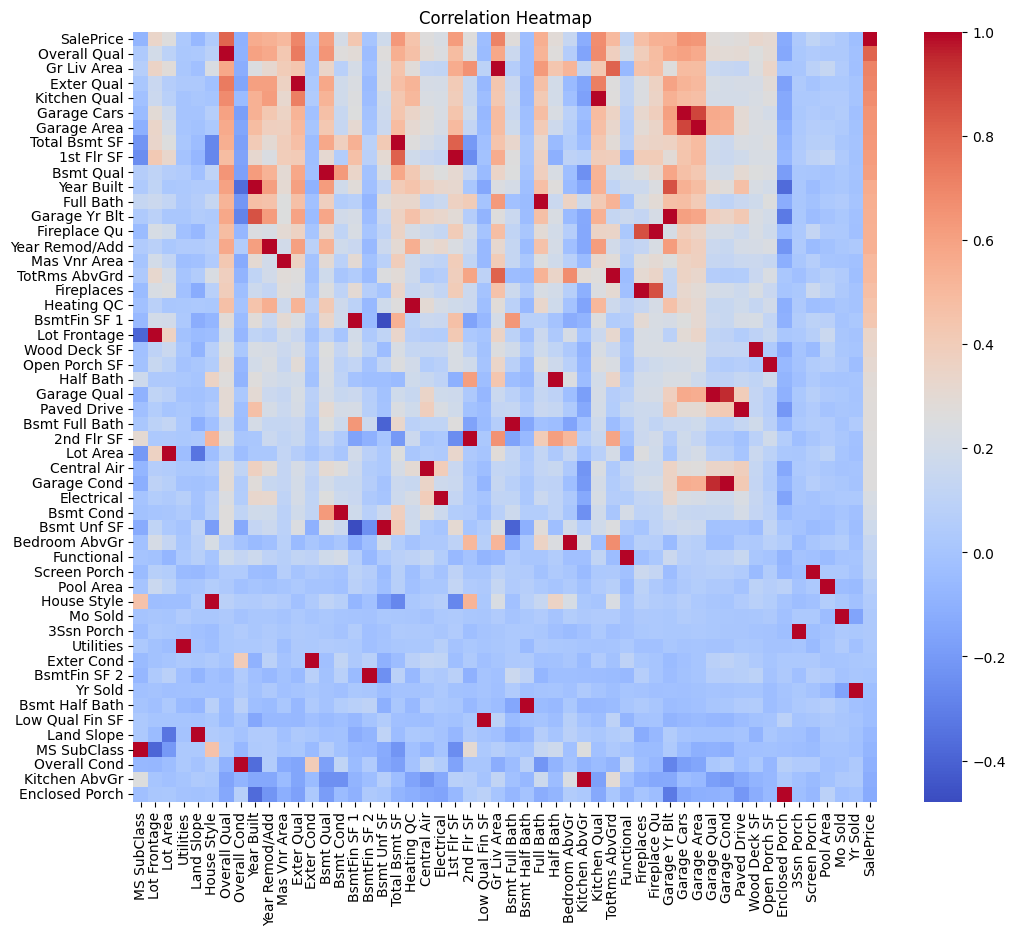

In [39]:
# Now for a correlation heatmap to visualize the relationships between the numerical features themselves
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap')
plt.show()

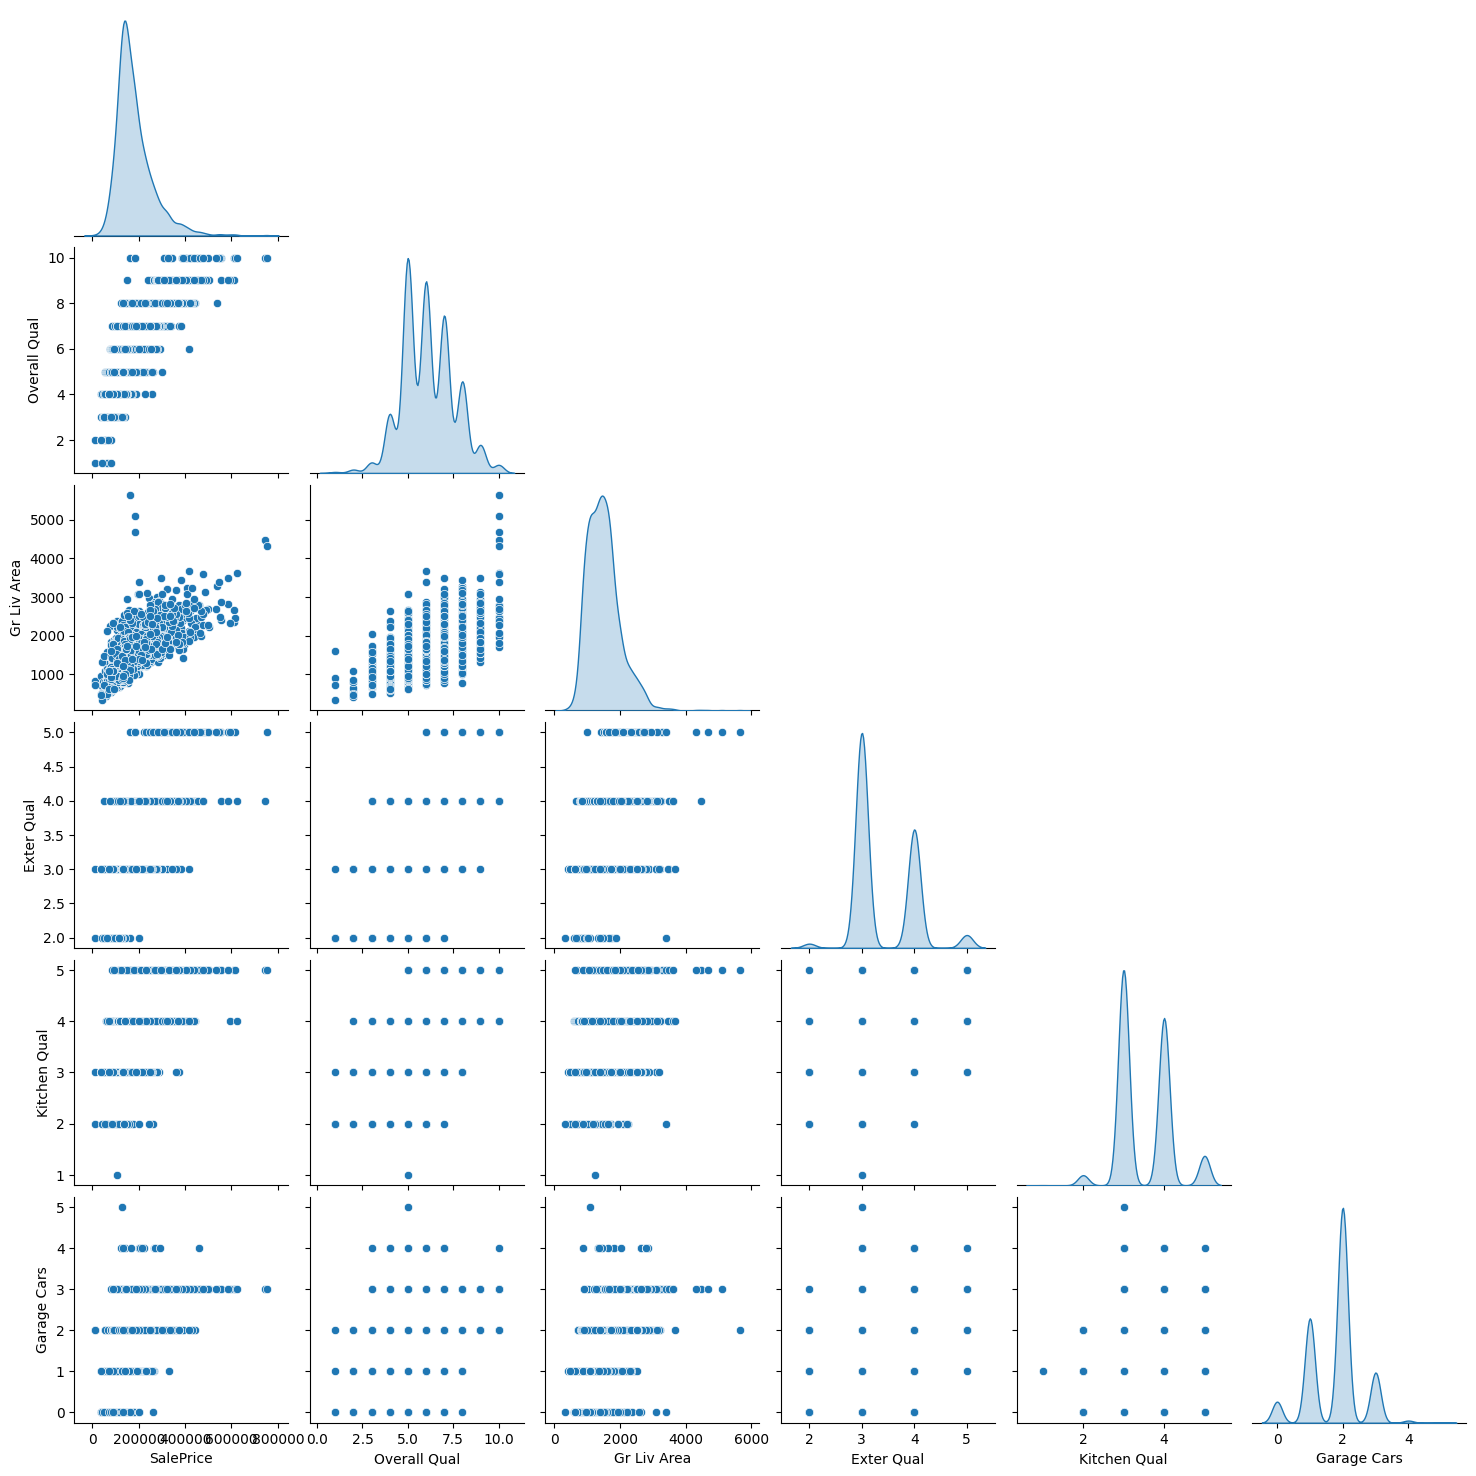

In [40]:
# Pairplot to visualize relationships between top 5 correlated features with SalePrice
top_5_features = corr['SalePrice'].abs().sort_values(ascending=False).index[:6]
sns.pairplot(df[top_5_features], diag_kind='kde', corner=True)
plt.show()

Looking at the pairplots, the 3/5 of the top 5 correlated features (Overall Qual, Exter Qual, Kitchen Qual) are categorical while the other 2 (Gr Liv Area and Garage Cars) are numerical.

Another thing about these features is that 4/5 are related to the quality of the house features. Overall quality of the house, quality of the house exterior, quality of the kitchen space and the living area in square feet that are above ground (Multiple floors).

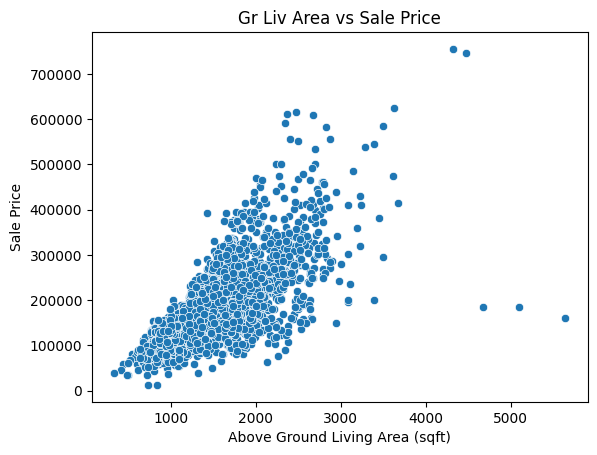

In [42]:
# On 2nd look at the pairplots, I realised that Gr Liv Area has a more linear relationship with SalePrice compared to Total Bsmt SF.
# And from that observation, there are a few outliers in Gr Liv Area that I would like to check.
sns.scatterplot(x=df['Gr Liv Area'], y=df['SalePrice'])
plt.title("Gr Liv Area vs Sale Price")
plt.xlabel("Above Ground Living Area (sqft)")
plt.ylabel("Sale Price")
plt.show()

In [43]:
df.loc[df['Gr Liv Area'] > 4000][['Sale Condition', 'Gr Liv Area', 'SalePrice']]

,Sale Condition,Gr Liv Area,SalePrice
1498,Partial,5642,160000
1760,Abnorml,4476,745000
1767,Normal,4316,755000
2180,Partial,5095,183850
2181,Partial,4676,184750


From these 5 outliers, I will drop the 3 partial sales as they may not truely represent its real and final market value.
The other 2 are definitely still acceptable as while they are way higher than the rest of the occurances, they still fit within the diagonal trend from bottom left to top right.

In [44]:
# Removing 3 outliers
features = features[features['Gr Liv Area'] <= 4500]

# Check larger values have been removed
features.loc[features['Gr Liv Area'] > 4000][['SalePrice', 'Gr Liv Area']]

,SalePrice,Gr Liv Area
1760,745000,4476
1767,755000,4316


Central Tendency

### Building A Linear Regression Model

### Model Validation

### Feature Engineering & Re-Evaluation